# Model Comparison

This notebook compares multiple machine learning classification models using the same dataset, preprocessing pipeline, training/test split, and evaluation metrics.

### Models compared

- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Support Vector Machine (SVM)
- K-Nearest Neighbors (KNN)

### Evaluation metrics

- Accuracy
- Precision
- Recall
- F1 Score

The goal is to determine which model performs best on the selected test dataset.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Locate the project root automatically
current_path = Path.cwd().resolve()
project_root = None

for path in [current_path, *current_path.parents]:
    if (path / "modules").is_dir():
        project_root = path
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the AutoML-Studio project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import modules.data_loader as data_loader
import modules.preprocessing as preprocessing
import modules.model_training as model_training
import modules.evaluation as evaluation

print("Project root:", project_root)

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Project root: C:\Users\PMLS\Documents\Coding\System-7-Internship\AutoML-Studio


In [2]:
sample_path = project_root / "sample_data" / "student-mat.csv"

if not sample_path.exists():
    raise FileNotFoundError(f"Dataset not found: {sample_path}")

df = data_loader.load_csv(sample_path)
data_loader.validate_dataset(df)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
target_column = "Passed"

df_model = df.copy()

if "G3" not in df_model.columns:
    raise ValueError("G3 column was not found.")

# Example classification target:
# G3 >= 10 -> Passed
# G3 < 10  -> Failed
df_model["Passed"] = (df_model["G3"] >= 10).astype(int)

# Remove G1, G2 and G3 to avoid using the final grade
# directly to predict the derived target.
columns_to_drop = [
    "G1",
    "G2",
    "G3"
]

columns_to_drop = [
    column for column in columns_to_drop
    if column in df_model.columns
]

df_model = df_model.drop(columns=columns_to_drop)

print("Target column:", target_column)

print("\nTarget distribution:")
display(df_model[target_column].value_counts())

Target column: Passed

Target distribution:


Passed
1    265
0    130
Name: count, dtype: int64

In [4]:
X, y = preprocessing.separate_features_target(
    df_model,
    target_column
)

numeric_columns, categorical_columns = (
    preprocessing.identify_column_types(X)
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

Feature shape: (395, 30)
Target shape: (395,)

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (316, 30)
Testing set: (79, 30)


In [6]:
preprocessor = preprocessing.build_preprocessor(
    numeric_columns,
    categorical_columns
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Models to compare:")
for model_name in models:
    print("-", model_name)

Models to compare:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Support Vector Machine
- K-Nearest Neighbors


In [8]:
results = []

trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )
    })

    trained_models[model_name] = pipeline

results_df = pd.DataFrame(results)

print("Model evaluation completed.")

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)

Model evaluation completed.


C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.658228,0.636698,0.658228,0.642231
1,Support Vector Machine,0.683544,0.653083,0.683544,0.639013
2,Random Forest,0.658228,0.619486,0.658228,0.619934
3,Decision Tree,0.607595,0.627203,0.607595,0.615093
4,Gradient Boosting,0.582278,0.569719,0.582278,0.575240
5,K-Nearest Neighbors,0.582278,0.540449,0.582278,0.554909


In [11]:
# results_df is already a comparison DataFrame,
# so it can be sorted directly.

comparison = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.658228,0.636698,0.658228,0.642231
1,Support Vector Machine,0.683544,0.653083,0.683544,0.639013
2,Random Forest,0.658228,0.619486,0.658228,0.619934
3,Decision Tree,0.607595,0.627203,0.607595,0.615093
4,Gradient Boosting,0.582278,0.569719,0.582278,0.575240
5,K-Nearest Neighbors,0.582278,0.540449,0.582278,0.554909


In [12]:
best_model_row = results_df.loc[
    results_df["F1 Score"].idxmax()
]

best_model_name = best_model_row["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("\nPerformance:")
display(
    best_model_row.to_frame().T
)

Best Model: Logistic Regression

Performance:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.658228,0.636698,0.658228,0.642231


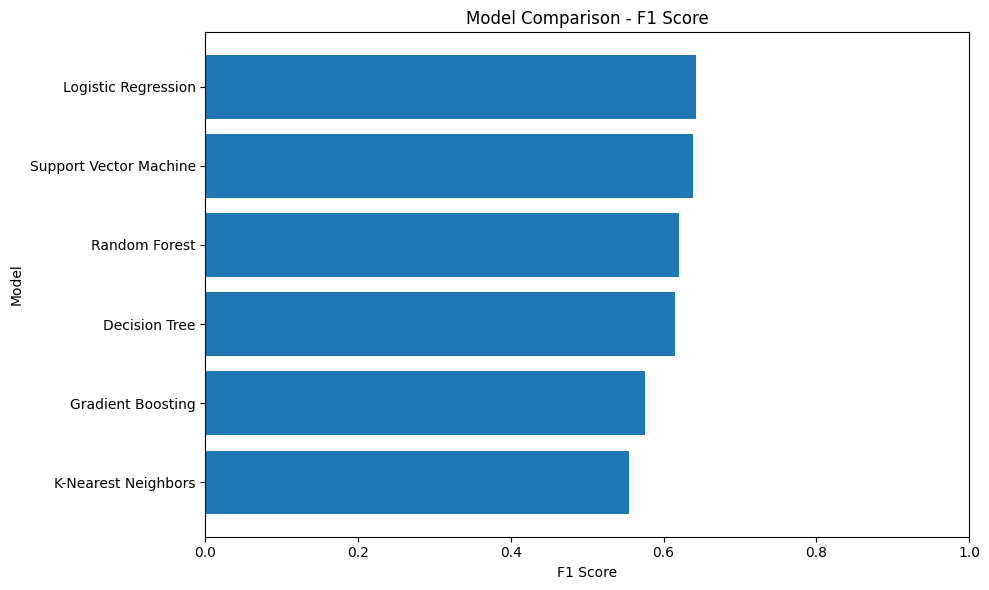

In [13]:
plot_df = results_df.sort_values(
    by="F1 Score",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Model"],
    plot_df["F1 Score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Model")
plt.title("Model Comparison - F1 Score")

plt.xlim(0, 1)
plt.tight_layout()

plt.show()

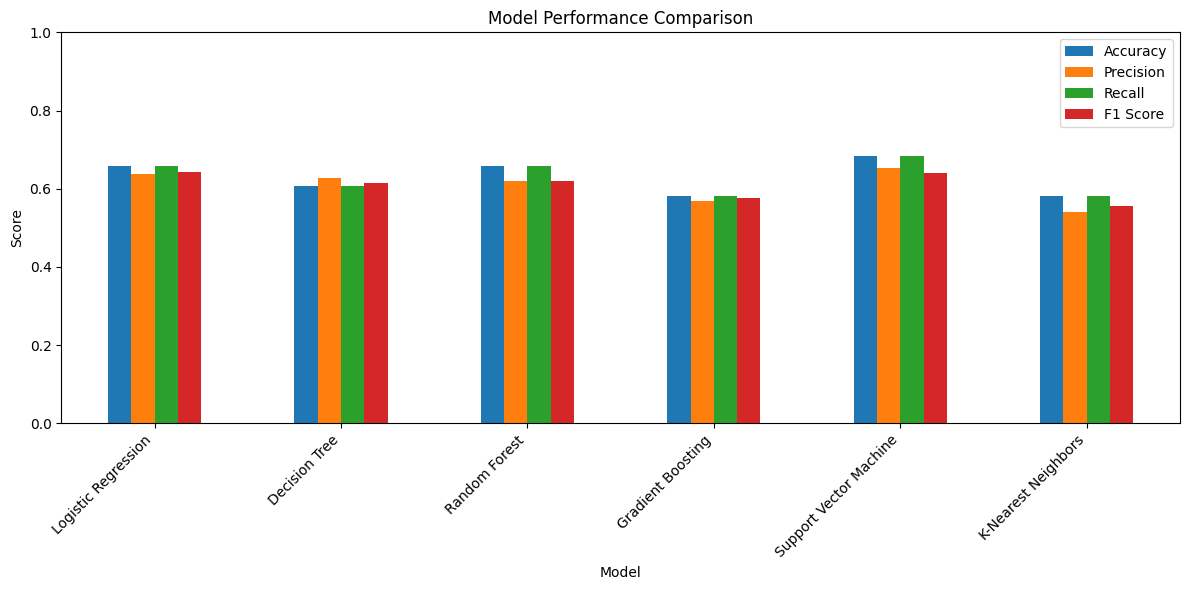

In [14]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

comparison_plot = results_df.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [15]:
y_best_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nAccuracy:")
print(
    accuracy_score(
        y_test,
        y_best_pred
    )
)

print("\nPrecision:")
print(
    precision_score(
        y_test,
        y_best_pred,
        average="weighted",
        zero_division=0
    )
)

print("\nRecall:")
print(
    recall_score(
        y_test,
        y_best_pred,
        average="weighted",
        zero_division=0
    )
)

print("\nF1 Score:")
print(
    f1_score(
        y_test,
        y_best_pred,
        average="weighted",
        zero_division=0
    )
)

Best Model: Logistic Regression

Accuracy:
0.6582278481012658

Precision:
0.6366977570508551

Recall:
0.6582278481012658

F1 Score:
0.6422314327321608


In [16]:
comparison_output = (
    results_df
    .sort_values(
        by="F1 Score",
        ascending=False
    )
    .reset_index(drop=True)
)

display(comparison_output)

# Save a local CSV for inspection.
output_path = project_root / "model_comparison_results.csv"

comparison_output.to_csv(
    output_path,
    index=False
)

print(f"\nComparison results saved to: {output_path}")

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.658228,0.636698,0.658228,0.642231
1,Support Vector Machine,0.683544,0.653083,0.683544,0.639013
2,Random Forest,0.658228,0.619486,0.658228,0.619934
3,Decision Tree,0.607595,0.627203,0.607595,0.615093
4,Gradient Boosting,0.582278,0.569719,0.582278,0.575240
5,K-Nearest Neighbors,0.582278,0.540449,0.582278,0.554909



Comparison results saved to: C:\Users\PMLS\Documents\Coding\System-7-Internship\AutoML-Studio\model_comparison_results.csv


# Conclusion

Multiple classification models were trained and evaluated using the same preprocessing pipeline and test set.

The models were compared using:

- Accuracy
- Precision
- Recall
- F1 Score

The model with the highest F1 Score was selected as the best-performing model for this experiment.

### Important

Model performance depends on the dataset, preprocessing, feature selection, train/test split, and evaluation methodology.

The `student-mat.csv` dataset is being used here as a development and learning dataset. The derived `Passed` target is only an example classification task and should not be interpreted as a real-world prediction system.

The reusable model-training and evaluation modules used by the main AutoML Studio application are located in:

- `modules/model_training.py`
- `modules/evaluation.py`

The Streamlit application uses the same general workflow dynamically for uploaded datasets.